# Week 8: Complete Directional Heading Estimation (0°–359°)

## 1. Setup and Imports

This section imports the required Python libraries and defines the project directories for Week 8.

The existing dataset of 100 vehicle crops from the DRASHTI-HaOBB dataset is used. The results, tables, and visualizations generated during this experiment are stored separately in the Week 8 directory.

In [3]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from math import atan2, degrees

BASE_DIR = Path("/content/drive/MyDrive/ECE501_DRASHTI")

WEEK6_DIR = BASE_DIR / "Week6_Results"
WEEK8_DIR = BASE_DIR / "Week8_Results"

TABLE_DIR = WEEK8_DIR / "tables"
VISUAL_DIR = WEEK8_DIR / "visualizations"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
VISUAL_DIR.mkdir(parents=True, exist_ok=True)

print("Setup complete.")

Setup complete.


## 2. Loading the Existing Vehicle Dataset

The existing 100 vehicle crops and their corresponding ground-truth heading annotations are loaded.

The vehicle crop manifest from Week 6 is merged with the Week 3 ground-truth results using Vehicle_ID.

The ground-truth heading is retained only for evaluating the estimated directional heading. It is not used during prediction.

In [4]:
manifest = pd.read_csv(
    WEEK6_DIR / "tables" / "01_vehicle_crop_manifest.csv"
)

ground_truth = pd.read_csv(
    BASE_DIR / "Week3_Results" / "week3_100_image_error_table.csv"
)

df = manifest.merge(
    ground_truth[["Vehicle_ID", "Ground_Truth_Heading_deg"]],
    on="Vehicle_ID",
    how="inner"
)

df = df.drop_duplicates("Vehicle_ID").reset_index(drop=True)

print("Total vehicles:", len(df))
print(df[["Vehicle_ID", "Ground_Truth_Heading_deg"]].head())

Total vehicles: 100
                 Vehicle_ID  Ground_Truth_Heading_deg
0  00XD_3rEO_4KVW_vehicle_1                     49.00
1  2GuW_AKSD_y8m2_vehicle_1                    182.36
2  2h07_apct_WjnB_vehicle_1                    168.38
3  3J2E_oL5U_TE2G_vehicle_1                      4.66
4  3LzM_y7ht_SdIz_vehicle_1                     24.90


## 3. Locating Vehicle Crops

This section defines a function to locate the vehicle crop images using their stored paths.

Both absolute paths and paths relative to the Week 6 vehicle crop directory are supported.

In [5]:
def get_crop_path(path_value):

    path = Path(str(path_value))

    if path.exists():
        return path

    alternative = WEEK6_DIR / "vehicle_crops" / path.name

    if alternative.exists():
        return alternative

    return None

## 4. Vehicle Axis Estimation Using Modified Hough Transform

The Modified Hough Transform developed and optimized in Week 6 is used to estimate the dominant longitudinal axis of each vehicle.

The preprocessing pipeline consists of:

1. Grayscale conversion.
2. Contrast enhancement using CLAHE.
3. Gaussian blurring to reduce noise.
4. Canny edge detection.
5. Morphological closing.
6. Probabilistic Hough Line Transform.

The detected line segments are filtered according to their lengths. The dominant angular bin is selected, and a weighted axial mean is calculated to estimate the vehicle's main axis.

The estimated axis is an undirected orientation and therefore cannot independently distinguish between two opposite vehicle directions.

In [6]:
def estimate_vehicle_axis(image):

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)

    blurred = cv2.GaussianBlur(enhanced, (5, 5), 0)

    edges = cv2.Canny(blurred, 50, 150)

    kernel = np.ones((3, 3), np.uint8)

    edges = cv2.morphologyEx(
        edges,
        cv2.MORPH_CLOSE,
        kernel
    )

    lines = cv2.HoughLinesP(
        edges,
        1,
        np.pi / 180,
        threshold=30,
        minLineLength=15,
        maxLineGap=5
    )

    if lines is None:
        return None, edges

    lines = np.asarray(lines).reshape(-1, 4)

    dx = lines[:, 2] - lines[:, 0]
    dy = lines[:, 3] - lines[:, 1]

    lengths = np.hypot(dx, dy)

    angles = np.degrees(np.arctan2(dy, dx)) % 180

    diagonal = np.hypot(image.shape[1], image.shape[0])

    valid = lengths >= 0.05 * diagonal

    angles = angles[valid]
    lengths = lengths[valid]

    if len(angles) == 0:
        return None, edges

    bins = np.arange(0, 181, 20)

    histogram, bin_edges = np.histogram(
        angles,
        bins=bins,
        weights=lengths
    )

    dominant_bin = np.argmax(histogram)

    selected = (
        (angles >= bin_edges[dominant_bin]) &
        (angles < bin_edges[dominant_bin + 1])
    )

    selected_angles = np.radians(angles[selected])
    selected_weights = lengths[selected]

    sin_sum = np.sum(selected_weights * np.sin(2 * selected_angles))
    cos_sum = np.sum(selected_weights * np.cos(2 * selected_angles))

    axis = (
        np.degrees(0.5 * np.arctan2(sin_sum, cos_sum)) % 180
    )

    return axis, edges

## 5. Directional Heading Estimation Using Silhouette Asymmetry

An additional image-processing stage is introduced to address the 180° ambiguity of the estimated vehicle axis.

The vehicle silhouette is extracted using Otsu thresholding and morphological closing. The extracted silhouette is aligned approximately with the estimated vehicle axis.

The distribution of foreground pixels on either side of the vehicle is compared to estimate which direction the vehicle may be facing.

Based on this comparison, the estimated axis is assigned to one of its two possible directional orientations, producing a heading in the range of 0°–359°.

This is an experimental heuristic. It does not guarantee accurate front-versus-rear identification for every vehicle.

In [7]:
def estimate_direction(image, axis):

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Separate vehicle from background using Otsu thresholding
    _, mask = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Try both polarities and retain the foreground
    candidates = [mask, cv2.bitwise_not(mask)]

    best_mask = None
    best_score = -1

    for candidate in candidates:

        candidate = cv2.morphologyEx(
            candidate,
            cv2.MORPH_CLOSE,
            np.ones((5, 5), np.uint8)
        )

        count = cv2.countNonZero(candidate)

        ratio = count / candidate.size

        if 0.02 < ratio < 0.90:
            score = abs(0.35 - ratio)

            if best_mask is None or score < best_score:
                best_mask = candidate
                best_score = score

    if best_mask is None:
        return None

    height, width = gray.shape

    # Rotate so the estimated axis is approximately horizontal
    center = (width / 2, height / 2)

    rotation = cv2.getRotationMatrix2D(
        center,
        -axis,
        1.0
    )

    rotated = cv2.warpAffine(
        best_mask,
        rotation,
        (width, height)
    )

    # Measure silhouette width in left and right halves
    middle = width // 2

    left_widths = np.count_nonzero(rotated[:, :middle], axis=1)
    right_widths = np.count_nonzero(rotated[:, middle:], axis=1)

    left_score = np.sum(left_widths ** 2)
    right_score = np.sum(right_widths ** 2)

    # Experimental directional rule:
    # choose the side with the larger silhouette score
    if right_score >= left_score:
        return axis % 180

    return (axis + 180) % 360

## 6. Applying the Method to All 100 Vehicles

The complete directional heading estimation pipeline is applied to all available vehicle crops.

For each vehicle:

1. The crop image is loaded.
2. Its longitudinal axis is estimated using Modified Hough Transform.
3. Its directional heading is estimated using silhouette asymmetry.
4. The estimated axis, directional heading, and ground-truth heading are recorded.

Vehicles for which the crop cannot be loaded or the axis cannot be estimated are excluded from successful predictions.

The resulting table contains the predictions for all successfully processed vehicles.

In [8]:
results = []

for index, row in df.iterrows():

    vehicle_id = row["Vehicle_ID"]

    crop_path = get_crop_path(row["Crop_Path"])

    if crop_path is None:
        print("Missing crop:", vehicle_id)
        continue

    image = cv2.imread(str(crop_path))

    if image is None:
        print("Unable to read:", vehicle_id)
        continue

    axis, edges = estimate_vehicle_axis(image)

    if axis is None:
        print("Axis not detected:", vehicle_id)
        continue

    heading = estimate_direction(image, axis)

    if heading is None:
        print("Direction not estimated:", vehicle_id)
        continue

    results.append({
        "Vehicle_ID": vehicle_id,
        "Estimated_Axis_deg": axis,
        "Estimated_Directional_Heading_deg": heading,
        "Ground_Truth_Heading_deg": row["Ground_Truth_Heading_deg"]
    })

    if (index + 1) % 10 == 0:
        print(f"Processed {index + 1}/{len(df)} vehicles")

results_df = pd.DataFrame(results)

print("\nSuccessfully processed:", len(results_df))

display(results_df.head())

Processed 10/100 vehicles
Processed 20/100 vehicles
Processed 30/100 vehicles
Processed 40/100 vehicles
Processed 50/100 vehicles
Processed 60/100 vehicles
Processed 70/100 vehicles
Processed 80/100 vehicles
Processed 90/100 vehicles
Processed 100/100 vehicles

Successfully processed: 100


,Vehicle_ID,Estimated_Axis_deg,Estimated_Directional_Heading_deg,Ground_Truth_Heading_deg
0,00XD_3rEO_4KVW_vehicle_1,49.314549,49.314549,49.00
1,2GuW_AKSD_y8m2_vehicle_1,9.372670,9.372670,182.36
2,2h07_apct_WjnB_vehicle_1,169.445736,169.445736,168.38
3,3J2E_oL5U_TE2G_vehicle_1,1.089514,181.089514,4.66
4,3LzM_y7ht_SdIz_vehicle_1,29.278397,29.278397,24.90


## 7. Directional Heading Error Calculation

The estimated directional heading is compared with the ground-truth heading provided by the dataset.

Since directional headings are circular measurements, the angular error is calculated using:

Error = min(|Estimated Heading - Ground Truth Heading|, 360° - |Estimated Heading - Ground Truth Heading|)

The following evaluation metrics are calculated:

- Mean Absolute Error (MAE)
- Median Angular Error
- Maximum Angular Error

These metrics evaluate the accuracy of the complete 0°–359° directional heading estimation.

In [9]:
def angular_error_360(estimated, actual):

    difference = abs(estimated - actual)

    return min(difference, 360 - difference)


results_df["Directional_Heading_Error_deg"] = results_df.apply(
    lambda row: angular_error_360(
        row["Estimated_Directional_Heading_deg"],
        row["Ground_Truth_Heading_deg"]
    ),
    axis=1
)

print("WEEK 8 RESULTS")
print("-----------------------")

print("Vehicles:", len(results_df))

print(
    "MAE:",
    round(results_df["Directional_Heading_Error_deg"].mean(), 2)
)

print(
    "Median:",
    round(results_df["Directional_Heading_Error_deg"].median(), 2)
)

print(
    "Maximum:",
    round(results_df["Directional_Heading_Error_deg"].max(), 2)
)

WEEK 8 RESULTS
-----------------------
Vehicles: 100
MAE: 82.02
Median: 13.35
Maximum: 179.91


## 8. Saving Experimental Results

The estimated axis, directional heading, ground-truth heading, and corresponding angular error are saved in a CSV file.

This file provides the basis for further analysis, comparison, and reporting of the Week 8 experiment.

In [10]:
output_file = TABLE_DIR / "week8_automatic_directional_heading.csv"

results_df.to_csv(output_file, index=False)

print("Saved:", output_file)

Saved: /content/drive/MyDrive/ECE501_DRASHTI/Week8_Results/tables/week8_automatic_directional_heading.csv


## 9. Directional Heading Error Distribution

A histogram is generated to visualize the distribution of directional heading errors across the successfully processed vehicle crops.

This visualization helps identify whether the estimation method produces consistently low errors or struggles with particular vehicle orientations.

The histogram is also saved in the Week 8 visualizations directory.

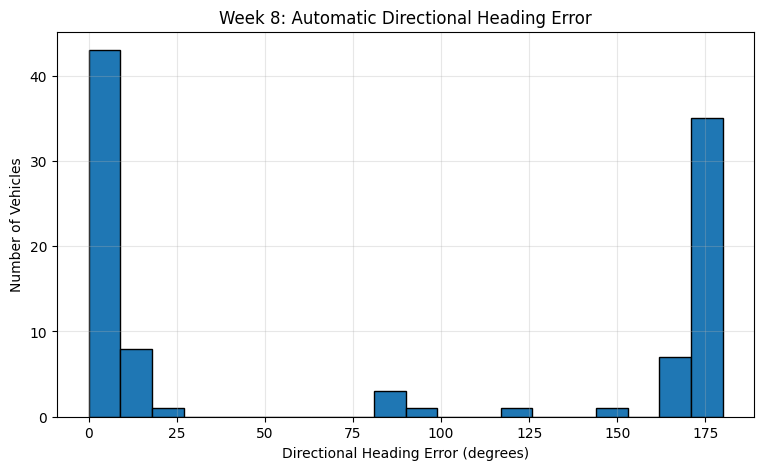

In [11]:
plt.figure(figsize=(9, 5))

plt.hist(
    results_df["Directional_Heading_Error_deg"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Directional Heading Error (degrees)")
plt.ylabel("Number of Vehicles")

plt.title("Week 8: Automatic Directional Heading Error")

plt.grid(alpha=0.3)

plt.savefig(
    VISUAL_DIR / "week8_directional_heading_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Visualizing Estimated and Ground-Truth Headings

The estimated directional headings are visualized on the original vehicle crops using directional arrows.

- **Green arrow:** Estimated directional heading.
- **Red arrow:** Ground-truth directional heading.

The visual comparison helps assess the alignment between the predicted and actual vehicle directions.

The vehicle ID, ground-truth heading, estimated heading, and angular error are displayed alongside each image.

The 100 successfully processed vehicles are displayed by default. The number can be increased to inspect the complete dataset.

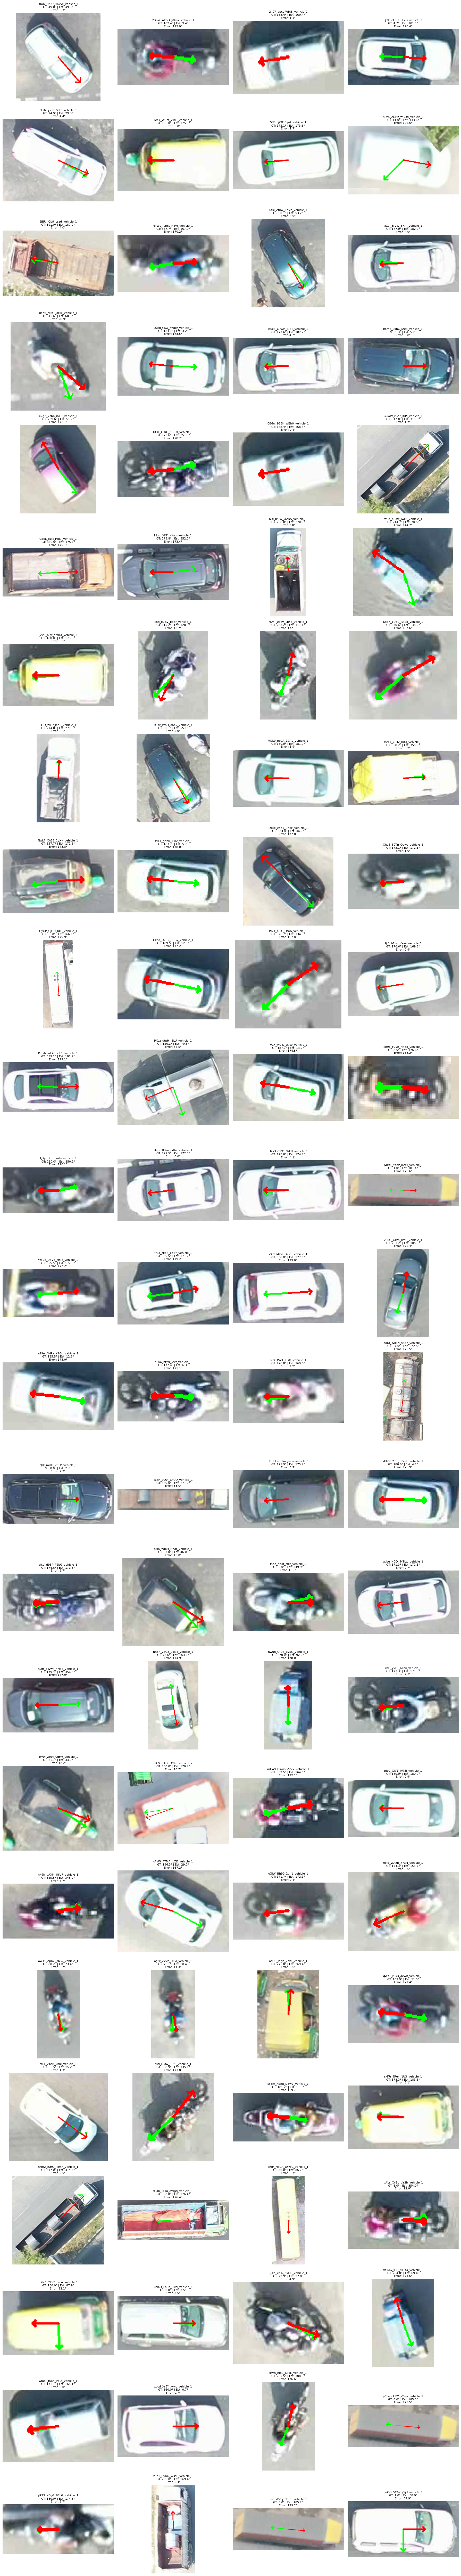

In [13]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from math import radians, cos, sin
import math

NUM_IMAGES = 100

def draw_heading_arrow(image, heading, color, label):

    height, width = image.shape[:2]

    center_x = width // 2
    center_y = height // 2

    length = min(width, height) * 0.4

    angle = radians(heading)

    end_x = int(center_x + length * cos(angle))
    end_y = int(center_y + length * sin(angle))

    cv2.arrowedLine(
        image,
        (center_x, center_y),
        (end_x, end_y),
        color,
        2,
        tipLength=0.15
    )

    return image


display_df = results_df.head(NUM_IMAGES).reset_index(drop=True)

columns = 4
rows = math.ceil(len(display_df) / columns)

plt.figure(figsize=(18, rows * 4))

for i, row in display_df.iterrows():

    vehicle_id = row["Vehicle_ID"]

    original_row = df[
        df["Vehicle_ID"] == vehicle_id
    ].iloc[0]

    crop_path = get_crop_path(original_row["Crop_Path"])

    image = cv2.imread(str(crop_path))

    if image is None:
        continue

    image = image.copy()

    # Draw estimated heading in green
    image = draw_heading_arrow(
        image,
        row["Estimated_Directional_Heading_deg"],
        (0, 255, 0),
        "Estimated"
    )

    # Draw ground-truth heading in red
    image = draw_heading_arrow(
        image,
        row["Ground_Truth_Heading_deg"],
        (0, 0, 255),
        "Ground Truth"
    )

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(rows, columns, i + 1)
    plt.imshow(image)

    plt.title(
        f"{vehicle_id}\n"
        f"GT: {row['Ground_Truth_Heading_deg']:.1f}° | "
        f"Est: {row['Estimated_Directional_Heading_deg']:.1f}°\n"
        f"Error: {row['Directional_Heading_Error_deg']:.1f}°",
        fontsize=8
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## 10. Saving Visualizations of All 100 Vehicles

This section generates and saves visual comparisons for all successfully processed vehicle crops.

Each visualization includes:

- **Green arrow:** Estimated directional heading.
- **Red arrow:** Ground-truth directional heading.
- Vehicle ID.
- Estimated heading and ground-truth heading.
- Directional angular error.

To avoid memory issues and prevent Google Colab from crashing, the visualizations are generated in batches of 20 images.

Each batch is saved as a separate high-resolution PNG file in the Week 8 visualizations directory.

In [14]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
import math
from math import radians, cos, sin
from pathlib import Path

NUM_IMAGES = 100
COLUMNS = 5
BATCH_SIZE = 20

def draw_heading_arrow(image, heading, color):

    height, width = image.shape[:2]

    center = (width // 2, height // 2)
    length = min(width, height) * 0.4

    angle = radians(heading)

    end = (
        int(center[0] + length * cos(angle)),
        int(center[1] + length * sin(angle))
    )

    cv2.arrowedLine(
        image, center, end, color, 2, tipLength=0.15
    )

    return image


display_df = results_df.head(NUM_IMAGES).reset_index(drop=True)

# Save visualizations in batches to avoid memory issues
for start in range(0, len(display_df), BATCH_SIZE):

    batch = display_df.iloc[start:start + BATCH_SIZE]

    rows = math.ceil(len(batch) / COLUMNS)

    fig, axes = plt.subplots(
        rows, COLUMNS,
        figsize=(20, rows * 4)
    )

    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for i, (_, row) in enumerate(batch.iterrows()):

        vehicle_id = row["Vehicle_ID"]

        original_row = df[
            df["Vehicle_ID"] == vehicle_id
        ].iloc[0]

        crop_path = get_crop_path(original_row["Crop_Path"])

        image = cv2.imread(str(crop_path))

        if image is None:
            continue

        image = image.copy()

        # Green = estimated heading
        image = draw_heading_arrow(
            image,
            row["Estimated_Directional_Heading_deg"],
            (0, 255, 0)
        )

        # Red = ground-truth heading
        image = draw_heading_arrow(
            image,
            row["Ground_Truth_Heading_deg"],
            (0, 0, 255)
        )

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        ax = axes[i]
        ax.imshow(image)

        ax.set_title(
            f"{vehicle_id}\n"
            f"GT: {row['Ground_Truth_Heading_deg']:.1f}° | "
            f"Est: {row['Estimated_Directional_Heading_deg']:.1f}°\n"
            f"Error: {row['Directional_Heading_Error_deg']:.1f}°",
            fontsize=8
        )

    plt.tight_layout()

    batch_number = start // BATCH_SIZE + 1

    output_path = (
        VISUAL_DIR /
        f"week8_directional_visualization_batch_{batch_number}.png"
    )

    fig.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.close(fig)

    print("Saved:", output_path)

print("\nAll visualization batches saved successfully.")

Saved: /content/drive/MyDrive/ECE501_DRASHTI/Week8_Results/visualizations/week8_directional_visualization_batch_1.png
Saved: /content/drive/MyDrive/ECE501_DRASHTI/Week8_Results/visualizations/week8_directional_visualization_batch_2.png
Saved: /content/drive/MyDrive/ECE501_DRASHTI/Week8_Results/visualizations/week8_directional_visualization_batch_3.png
Saved: /content/drive/MyDrive/ECE501_DRASHTI/Week8_Results/visualizations/week8_directional_visualization_batch_4.png
Saved: /content/drive/MyDrive/ECE501_DRASHTI/Week8_Results/visualizations/week8_directional_visualization_batch_5.png

All visualization batches saved successfully.


## 11. Week 8 Experimental Conclusion

In this experiment, the existing Modified Hough Transform-based vehicle axis estimator was extended with a silhouette-asymmetry-based directional estimation stage.

The objective was to extend the estimated orientation from an undirected axis to a directional heading in the range of 0°–359°.

The performance was evaluated using the ground-truth heading annotations of the existing 100 vehicle crops. Directional angular error, MAE, median error, and maximum error were calculated.

The visualizations provide a qualitative comparison between estimated and ground-truth headings.

The silhouette-based direction estimation is a heuristic and may not correctly distinguish the front and rear of every vehicle. Therefore, the results must be interpreted as experimental estimates rather than guaranteed directional identification.